# **MNIST**

# **Problem Statement**

## **Business Context**

***Handwritten digit recognition is a common image-classification task. Automating it can help process forms, postal codes, and other documents where digits are written by hand. In this notebook, several neural-network configurations are compared to see how training choices and model architecture affect digit classification.***

## **Objective**

***The objective is to train a neural network to classify grayscale images into one of ten digit classes, from 0 to 9. The notebook experiments with different numbers of epochs, batch sizes, hidden-layer sizes, and activation functions, then compares training and validation performance.***

## **Data Description**

***The MNIST dataset contains grayscale images of handwritten digits. Each image is 28 × 28 pixels, and its label is an integer from 0 to 9. The dataset provides 60,000 images for training and 10,000 separate images for testing.***

# **Importing the neccessary Libraries**

In [1]:
!pip install --upgrade tensorflow scikit-learn pandas numpy matplotlib seaborn

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

import time

import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.models import Sequential
from keras.layers import Dense

*The imported libraries support numerical operations, data handling, plotting, splitting the dataset, measuring training time, and building neural networks with TensorFlow and Keras. A fixed random seed and deterministic operations are also configured so the experiment is more reproducible.*

In [2]:
keras.utils.set_random_seed(812)

tf.config.experimental.enable_op_determinism()

# **Loading the data**

In [3]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

*The MNIST dataset is loaded from Keras. It returns separate training and test sets, with each set containing images and their corresponding digit labels.*

# **Data Overview**

*The following shape checks show how many images and labels are available and the dimensions of each image. They also help confirm that each image has a corresponding label.*

In [4]:
print(x_train.shape, y_train.shape)
print(x_test.shape, y_test.shape)

(60000, 28, 28) (60000,)
(10000, 28, 28) (10000,)


*The training data contains 60,000 images and 60,000 labels; the test data contains 10,000 images and 10,000 labels. Each image is 28 × 28 pixels, and each label identifies the digit shown in its image.*

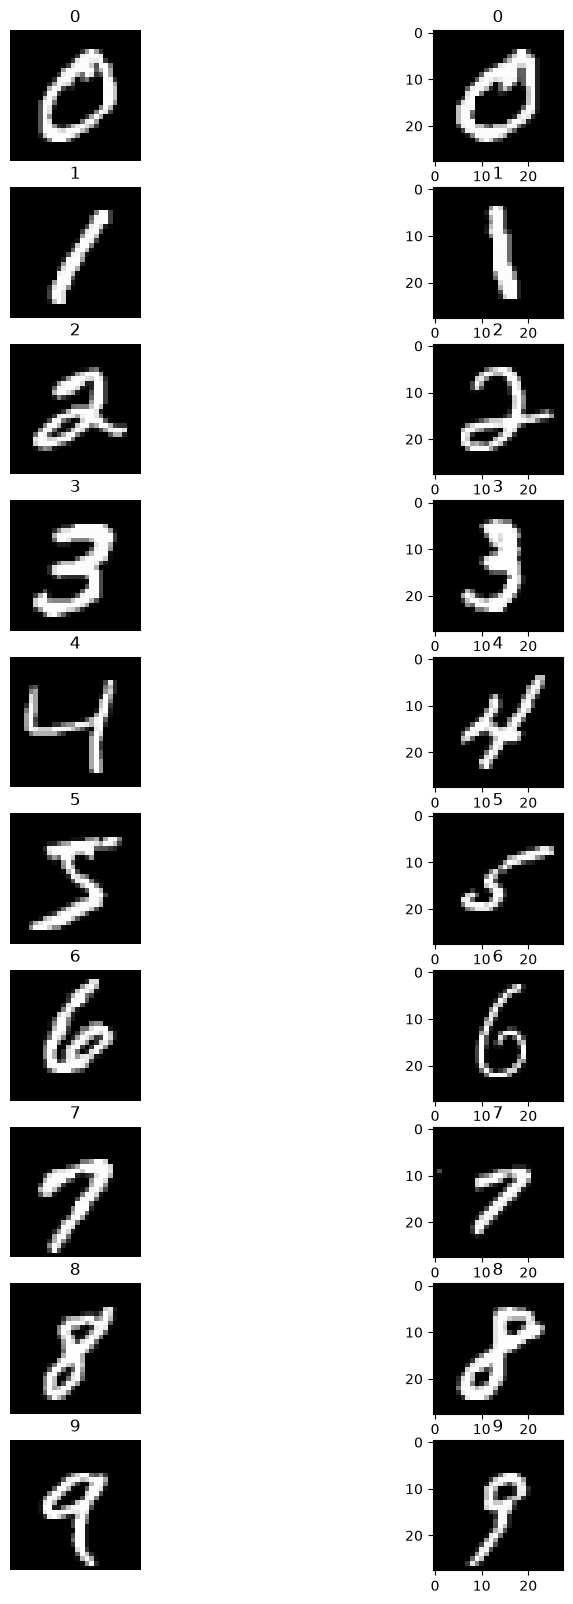

In [5]:
f, axarr = plt.subplots(10,2,figsize=(10,20))
for i in range(10): #for each digit
    images = x_train[y_train==i] #get all images of that digit
    axarr[i,0].imshow(images[0], cmap='gray')
    axarr[i,1].imshow(images[1], cmap='gray')
    axarr[i,0].axis('off')
    axarr[i,1].axis('on')
    axarr[i,0].set_title(str(i))
    axarr[i,1].set_title(str(i))

### *Image samples*

*The grid displays two example images for each digit, from 0 through 9. It gives a visual sense of the handwriting variation within each class: images can have the same label while differing in shape, slant, or thickness.*


# **Exploratory Data Analysis**

*The next plots examine how frequently each digit appears in the training and test sets. Checking class counts helps identify whether some digit classes are underrepresented.*

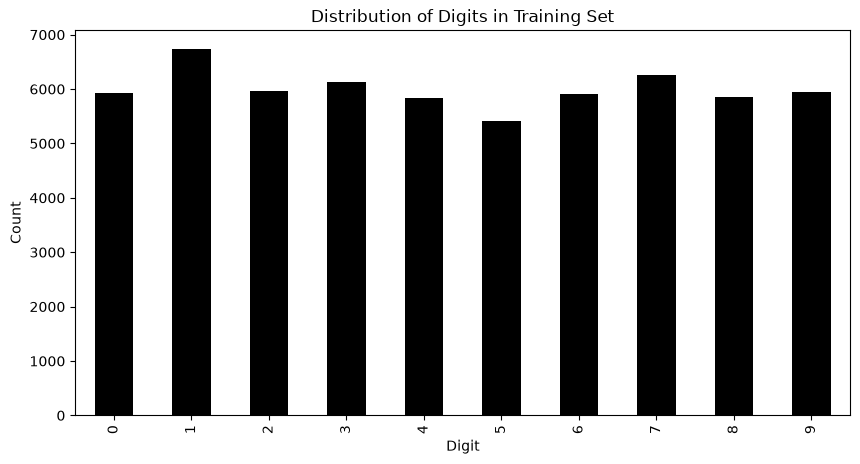

In [6]:
#frequency plot of the dependent variable (y_train)
(pd.Series(y_train).value_counts())[[0,1,2,3,4,5,6,7,8,9]].plot(kind='bar', figsize=(10,5), color='black')
plt.title('Distribution of Digits in Training Set')
plt.xlabel('Digit')
plt.ylabel('Count')
plt.show()

*The training-set chart shows the number of examples for each digit class. Comparing its bar heights helps reveal whether the training data is reasonably balanced or whether some digits appear much more often than others.*

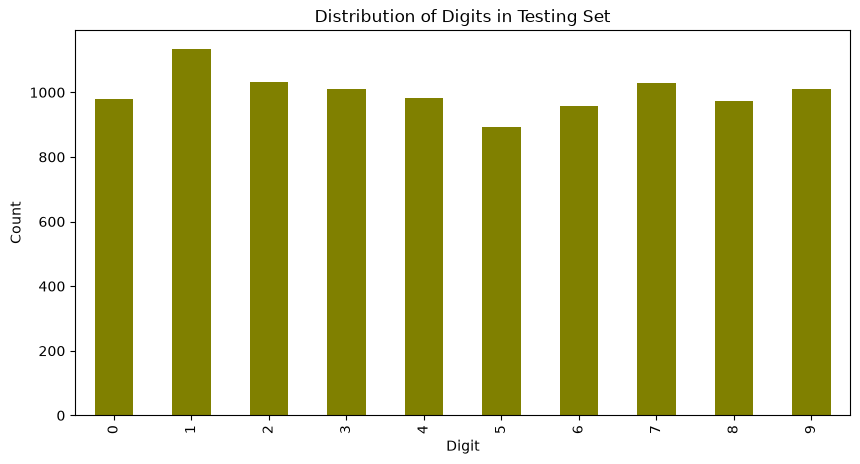

In [7]:
(pd.Series(y_test).value_counts())[[0,1,2,3,4,5,6,7,8,9]].plot(kind='bar', figsize=(10,5), color='olive')
plt.title('Distribution of Digits in Testing Set')
plt.xlabel('Digit')
plt.ylabel('Count')
plt.show()

### *Class distribution*

*The training and test plots show examples from all ten digit classes, with no single class overwhelmingly dominating. This gives a reasonably balanced basis for comparing per-class learning, although overall accuracy alone will not reveal which digits are most often confused.*

# **Data Pre-Processing**

***The images and labels are prepared for model training. This includes creating a validation split, scaling pixel values, flattening each image for the dense layers, and converting labels into a format suitable for multi-class classification.***

## *Train-Test Splitting*

*The original MNIST training set is divided into training and validation portions. Stratification preserves the approximate distribution of digit classes in both portions, while the separate test set remains reserved for later evaluation.*

In [8]:
#splitting the training dataset into 5:1 ratio for training and validation datasets
x_train, x_val, y_train, y_val = train_test_split(x_train, y_train, test_size=1-(5/6), random_state=42, stratify=y_train)

*The split creates five training examples for every one validation example. The fixed random state makes the split reproducible, and stratification helps ensure that all digit classes are represented proportionally in both sets.*

In [9]:
print(x_train.shape)
print(x_val.shape)
print(y_train.shape)
print(y_val.shape)

(50000, 28, 28)
(10000, 28, 28)
(50000,)
(10000,)


*The original 60,000 training images are divided into 50,000 training images and 10,000 validation images. The original 10,000-image test set remains separate and should be used only for final evaluation.*

## *Data Scaling*

*Each pixel is stored as an integer between 0 and 255. Scaling these values to a smaller range makes the inputs more consistent for optimization during neural-network training.*

In [10]:
#printing the maximum val and minimum  val of the independent variable
print(x_train.max(),x_test.max(),x_val.max())
print(x_train.min(),x_test.min(),x_val.min())

255 255 255
0 0 0


*These values confirm the pixel-value range before normalization. For grayscale images, the minimum is 0 and the maximum is 255, representing the darkest and brightest pixel intensities.*

In [11]:
#Normalizing the independent variable by dividing by 255 to bring the values between 0 and 1
x_train,x_val,x_test = x_train.astype('float32')/255, x_val.astype('float32')/255, x_test.astype('float32')/255

*Dividing each pixel by 255 converts the image values from the 0–255 range to the 0–1 range. This scaling is applied consistently to the training, validation, and test images.*

In [12]:
print(x_train.max(),x_test.max(),x_val.max())
print(x_train.min(),x_test.min(),x_val.min())

1.0 1.0 1.0
0.0 0.0 0.0


*The printed minimums and maximums confirm that normalization succeeded: the images now contain values between 0 and 1.*

## *Re-Shaping*

*Each image is originally a 28 × 28 grid of pixel values. The dense neural-network layers expect a one-dimensional feature vector, so each image will be flattened into 784 values while keeping all pixel information.*

In [13]:
x_train = x_train.reshape(x_train.shape[0], -1)
x_val = x_val.reshape(x_val.shape[0], -1)
x_test = x_test.reshape(x_test.shape[0], -1)

*The training, validation, and test images have each been reshaped from 28 × 28 arrays into vectors of 784 pixel values. The number of images in each set remains unchanged.*

In [14]:
x_train.shape

(50000, 784)

*The shape (50000, 784) means there are 50,000 training images, with each image represented by 784 features—one for each pixel.*

In [15]:
print("train samples:",x_train.shape[0])
print("validation samples:",x_val.shape[0])
print("test samples:",x_test.shape[0])

train samples: 50000
validation samples: 10000
test samples: 10000


### *Prepared inputs and split*

*The original 60,000 training images are divided into **50,000 training** and **10,000 validation** examples using a stratified split; the separate **10,000-example test set** remains untouched. Pixel values have been scaled to **[0, 1]**, and each 28 ? 28 image is flattened into **784 features** for the dense layers.*

## *Encoding the target variable*

*The target labels identify one of ten classes, corresponding to digits 0 through 9. The model will produce ten output values, so the labels are converted to a matching format.*

In [16]:
num_classes = 10

*There are ten possible classes in this task: the digits 0, 1, 2, 3, 4, 5, 6, 7, 8, and 9. This value determines the size of the model’s output layer and the encoded label vectors.*

In [17]:
y_train = keras.utils.to_categorical(y_train, num_classes)
y_test = keras.utils.to_categorical(y_test, num_classes)
y_val = keras.utils.to_categorical(y_val, num_classes)

*Each digit label is converted into a one-hot vector with ten positions. The position corresponding to the correct digit is 1, and all other positions are 0. This encoding matches the model’s ten-class softmax output.*

In [18]:
y_train

array([[0., 0., 0., ..., 1., 0., 0.],
       [0., 1., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 1.],
       ...,
       [0., 0., 0., ..., 0., 0., 1.],
       [0., 1., 0., ..., 0., 0., 0.],
       [0., 0., 1., ..., 0., 0., 0.]], shape=(50000, 10))

*The displayed array shows examples of the one-hot encoding. Each row represents one image label and contains a single active position corresponding to that image’s digit class.*

### *We'll create a dataframe to store the results from all the models we build*

In [19]:
#Defining the columns for the results dataframe
columns=["Hidden layers","Neurons-Hidden layer","Activation function-Hidden layer","Epochs","Batch size","Train loss","Train accuracy","Validation loss","Validation accuracy","time(secs)"]

#creating a dataframe in pandas
results =pd.DataFrame(columns=columns)

*A results table is created to record each model’s architecture and training configuration, along with its final training and validation loss, accuracy, and elapsed training time. This makes it easier to compare the experiments.*

# *Model-0*

*Model 0 serves as a baseline. It has a softmax output layer but no hidden layer, allowing its performance to be compared with later models that include additional layers or use different training settings.*

In [20]:
import gc

#clearing the keras session and garbage collection to free up memory
tf.keras.backend.clear_session()

#Garbage collection to free up memory
gc.collect()

0

*The Keras session is cleared and unused memory is collected before building the model. This helps keep separate experiments from reusing state or resources from previous models.*

In [21]:
#initializing the neural network
model=Sequential()

#adding a dense layer with softmax activation function,with the number of neurons equal to the number of classes in the output layer    
model.add(Dense(num_classes,activation='softmax',input_dim=x_train.shape[1]))

c:\Users\ushan\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\core\dense.py:103: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


*The model maps the 784 input pixel values directly to ten output classes using a softmax layer. With no hidden layer, it has limited ability to learn complex patterns in handwriting, making it a simple baseline rather than a high-capacity image classifier.*

In [22]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │         7,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,850 (30.66 KB)

 Trainable params: 7,850 (30.66 KB)

 Non-trainable params: 0 (0.00 B)

*The model summary shows the output shape and number of trainable parameters. The output has ten values—one per digit class—and the summary helps verify the network structure before training.*

In [23]:
#compiling the model
model.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])

*The model is configured to use categorical cross-entropy loss, which is appropriate for one-hot encoded multi-class labels. Stochastic gradient descent (SGD) is the optimizer, and accuracy is tracked as a performance metric.*

In [24]:
batch_size=x_train.shape[0]
epochs=10

start_time = time.time()

history=model.fit(
    x_train,y_train,validation_data=(x_val,y_val),
    batch_size=batch_size,
    epochs=epochs
)

end_time = time.time()

Epoch 1/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.0933 - loss: 2.3785 - val_accuracy: 0.1019 - val_loss: 2.3576
Epoch 2/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 321ms/step - accuracy: 0.0996 - loss: 2.3633 - val_accuracy: 0.1081 - val_loss: 2.3429
Epoch 3/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 219ms/step - accuracy: 0.1053 - loss: 2.3485 - val_accuracy: 0.1159 - val_loss: 2.3286
Epoch 4/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 184ms/step - accuracy: 0.1115 - loss: 2.3342 - val_accuracy: 0.1224 - val_loss: 2.3148
Epoch 5/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 191ms/step - accuracy: 0.1180 - loss: 2.3203 - val_accuracy: 0.1286 - val_loss: 2.3014
Epoch 6/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 228ms/step - accuracy: 0.1244 - loss: 2.3068 - val_accuracy: 0.1342 - val_loss: 2.2882
Epoch 7/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 212ms/step - accuracy: 0.1313 - loss: 2.2936 - val_accuracy: 0.1408 - val_loss: 2.2755
Epoch 8/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 260ms/step - accuracy: 0.1380 - loss: 2.2807 - val_accuracy: 0.1480 - val_loss: 2.

***columns=["Hidden layers","Neurons-Hidden layer","Activation function-Hidden layer","Epochs","Batch size","Train loss","Train accuracy","Validation loss","Validation accuracy","time(secs)"]***

*Model 0 is trained for 10 epochs using a batch size equal to the full training-set size. Training and validation metrics are recorded each epoch, and the elapsed time is measured for comparison with later experiments.*

*The final epoch’s loss and accuracy values are added to the results table along with the model configuration and training time. These values summarize this run for comparison with the later models.*

In [25]:
results.loc[0]= [0,'-','-',10,50000,history.history['loss'][-1],history.history['accuracy'][-1],history.history['val_loss'][-1],history.history['val_accuracy'][-1],end_time-start_time]

In [26]:
results

,Hidden layers,Neurons-Hidden layer,Activation function-Hidden layer,Epochs,Batch size,Train loss,Train accuracy,Validation loss,Validation accuracy,time(secs)
0,0,-,-,10,50000,2.255868,0.1527,2.238811,0.1628,3.643463


*This softmax-only baseline reaches **16.28% validation accuracy** (loss **2.239**) after 10 epochs. With no hidden layer and the entire training set in each batch, learning is limited; this is a useful baseline rather than a practical classifier.*

# *Model-1*

In [27]:
#clearing the keras session and garbage collection to free up memory
tf.keras.backend.clear_session()

*The Keras session is cleared before creating Model 1. This resets model-related state from the previous experiment and helps ensure that the new model is built independently. It also helps release resources used by the earlier model.*

In [28]:
#initailizing the neural network
model=Sequential()
model.add(Dense(num_classes,activation='softmax',input_dim=x_train.shape[1]))

c:\Users\ushan\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\core\dense.py:103: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


***Model 1 uses the same simple architecture as Model 0:*** *one Dense output layer with 10 units and a softmax activation. The input consists of 784 pixel values per image, and the 10 output values represent the model’s predicted probabilities for digits 0 through 9. Because there are no hidden layers, this model is a linear classifier and may not capture the more complex patterns in handwritten digits.*

In [29]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │         7,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,850 (30.66 KB)

 Trainable params: 7,850 (30.66 KB)

 Non-trainable params: 0 (0.00 B)

***The summary confirms that the network has one Dense layer with an output shape of 10 values per image. It contains 7,850 trainable parameters:*** 
*784 weights and one bias for each of the 10 output units. There are no non-trainable parameters.*

In [30]:
#compiling the model
model.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])

*The model is configured with categorical cross-entropy loss, which compares its 10-class predictions with the one-hot encoded digit labels. Stochastic gradient descent (SGD) is used to adjust the model’s weights, and accuracy is tracked to show the proportion of correctly classified images.*

In [31]:
batch_size=x_train.shape[0]
epochs=50

start_time = time.time()

history=model.fit(
    x_train,y_train,validation_data=(x_val,y_val),
    batch_size=batch_size,
    epochs=epochs
)

end_time = time.time()

Epoch 1/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 967ms/step - accuracy: 0.0724 - loss: 2.4184 - val_accuracy: 0.0749 - val_loss: 2.4064
Epoch 2/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 319ms/step - accuracy: 0.0750 - loss: 2.4036 - val_accuracy: 0.0784 - val_loss: 2.3921
Epoch 3/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 307ms/step - accuracy: 0.0777 - loss: 2.3893 - val_accuracy: 0.0819 - val_loss: 2.3783
Epoch 4/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 220ms/step - accuracy: 0.0804 - loss: 2.3754 - val_accuracy: 0.0847 - val_loss: 2.3649
Epoch 5/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 176ms/step - accuracy: 0.0844 - loss: 2.3619 - val_accuracy: 0.0879 - val_loss: 2.3518
Epoch 6/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 171ms/step - accuracy: 0.0879 - loss: 2.3487 - val_accuracy: 0.0912 - val_loss: 2.3390
Epoch 7/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 179ms/step - accuracy: 0.0916 - loss: 2.3359 - val_accuracy: 0.0951 - val_loss: 2.3265
Epoch 8/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 172ms/step - accuracy: 0.0961 - loss: 2.3234 - val_accuracy: 0.1005 - val_loss:

*Model 1 is trained for 50 epochs, using a batch size of 50,000—the entire training set. At the end of training, it reaches **43.06%** training accuracy and **43.32%** validation accuracy, with a validation loss of 1.924. The validation accuracy improves steadily during training, but the final result remains limited. Since this model has no hidden layer and makes only one weight update per epoch with full-batch training, its ability to learn complex digit patterns is restricted.*

In [32]:
results.loc[1]= [0,'-','-',50,50000,history.history['loss'][-1],history.history['accuracy'][-1],history.history['val_loss'][-1],history.history['val_accuracy'][-1],round(end_time-start_time,2)]

*This cell adds Model 1’s configuration and final training metrics to the results table. It records zero hidden layers, 50 epochs, a batch size of 50,000, the final training and validation losses and accuracies, and the elapsed training time. This enables a direct comparison with Model 0 and the later models.*

In [33]:
results

,Hidden layers,Neurons-Hidden layer,Activation function-Hidden layer,Epochs,Batch size,Train loss,Train accuracy,Validation loss,Validation accuracy,time(secs)
0,0,-,-,10,50000,2.255868,0.1527,2.238811,0.1628,3.643463
1,0,-,-,50,50000,1.927448,0.4306,1.924149,0.4332,10.980000


*The results table shows that Model 1 improves substantially over Model 0: validation accuracy rises from **16.28% to 43.32%**, while validation loss falls from **2.239 to 1.924**. Both models use the same architecture and batch size, so the main change is training duration: Model 1 runs for 50 epochs instead of 10. Although longer training helps, the classifier remains relatively weak.*

# *Model-2*

In [34]:
#clearing the keras session and garbage collection to free up memory
tf.keras.backend.clear_session()

*The Keras session is cleared before building Model 2. This resets model-related state from the previous experiment and helps ensure that Model 2 is created independently. The model architecture will be the same as the earlier softmax-only models, but its training batch size will be smaller.*

In [35]:
#initailizing the neural network
model=Sequential()
model.add(Dense(num_classes,activation='softmax',input_dim=x_train.shape[1]))

c:\Users\ushan\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\core\dense.py:103: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


*Model 2 has a single Dense output layer with 10 softmax units, one for each digit from 0 through 9. It receives 784 pixel values per image. Because it has no hidden layers, it is a simple linear classifier; the main change in this experiment is the training configuration rather than the network architecture.*

In [36]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │         7,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,850 (30.66 KB)

 Trainable params: 7,850 (30.66 KB)

 Non-trainable params: 0 (0.00 B)

*The summary confirms that the model produces **10 outputs for each input image and has 7,850 trainable parameters**. It has one Dense layer and no non-trainable parameters. This is the same architecture used in Models 0 and 1.*

In [37]:
#compiling the model
model.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])

*The model uses categorical cross-entropy loss, which is appropriate for the one-hot encoded labels and the ten-class softmax output. The SGD optimizer updates the model’s weights, and accuracy is tracked during training and validation.*

In [38]:
batch_size=32
epochs=10

start_time = time.time()

history=model.fit(
    x_train,y_train,validation_data=(x_val,y_val),
    batch_size=batch_size,
    epochs=epochs
)

end_time = time.time()

Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8100 - loss: 0.8307 - val_accuracy: 0.8664 - val_loss: 0.5345
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8780 - loss: 0.4763 - val_accuracy: 0.8816 - val_loss: 0.4439
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8885 - loss: 0.4176 - val_accuracy: 0.8895 - val_loss: 0.4068
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8941 - loss: 0.3885 - val_accuracy: 0.8935 - val_loss: 0.3855
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8982 - loss: 0.3702 - val_accuracy: 0.8972 - val_loss: 0.3712
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9014 - loss: 0.3572 - val_accuracy: 0.9001 - val_loss: 0.3609
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9038 - loss: 0.3474 - val_accuracy: 0.9023 - val_loss: 0.3529
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9058 - loss: 0.3396 - 

*Model 2 is trained for 10 epochs with a batch size of 32. Unlike Models 0 and 1, which use the entire training set in one batch, Model 2 updates its weights after each mini-batch. At the final epoch it achieves 90.84% training accuracy and 90.64% validation accuracy, with a validation loss of 0.337. The close training and validation accuracies suggest similar performance on these two sets.*

In [39]:
results.loc[2]= [0,'-','-',10,32,history.history['loss'][-1],history.history['accuracy'][-1],history.history['val_loss'][-1],history.history['val_accuracy'][-1],round(end_time-start_time,2)]

*This cell adds Model 2’s configuration and final metrics to the results table. It records zero hidden layers, 10 epochs, a batch size of 32, the final training and validation losses and accuracies, and the elapsed training time.*

In [40]:
results

,Hidden layers,Neurons-Hidden layer,Activation function-Hidden layer,Epochs,Batch size,Train loss,Train accuracy,Validation loss,Validation accuracy,time(secs)
0,0,-,-,10,50000,2.255868,0.1527,2.238811,0.1628,3.643463
1,0,-,-,50,50000,1.927448,0.4306,1.924149,0.4332,10.980000
2,0,-,-,10,32,0.327818,0.9084,0.336882,0.9064,42.210000


*The table shows that Model 2 achieves **90.64% validation accuracy**, compared with **16.28% for Model 0 and 43.32% for Model 1**. All three use the same softmax-only architecture; Model 2’s key change is using mini-batches of 32 instead of a full batch of 50,000. In this run, mini-batch training led to a major improvement in validation performance.*

# *Model-3*

In [41]:
tf.keras.backend.clear_session()

In [42]:
#initailizing the neural network
model=Sequential()
model.add(Dense(num_classes,activation='softmax',input_dim=x_train.shape[1]))

c:\Users\ushan\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\core\dense.py:103: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [43]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │         7,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,850 (30.66 KB)

 Trainable params: 7,850 (30.66 KB)

 Non-trainable params: 0 (0.00 B)

In [44]:
#compiling the model
model.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])

In [45]:
batch_size=32
epochs=50

start_time = time.time()

history=model.fit(
    x_train,y_train,validation_data=(x_val,y_val),
    batch_size=batch_size,
    epochs=epochs
)

end_time = time.time()

Epoch 1/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8076 - loss: 0.8325 - val_accuracy: 0.8664 - val_loss: 0.5355
Epoch 2/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8777 - loss: 0.4767 - val_accuracy: 0.8811 - val_loss: 0.4447
Epoch 3/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8882 - loss: 0.4180 - val_accuracy: 0.8892 - val_loss: 0.4072
Epoch 4/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8938 - loss: 0.3887 - val_accuracy: 0.8939 - val_loss: 0.3856
Epoch 5/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8977 - loss: 0.3703 - val_accuracy: 0.8967 - val_loss: 0.3712
Epoch 6/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9009 - loss: 0.3572 - val_accuracy: 0.8992 - val_loss: 0.3607
Epoch 7/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9038 - loss: 0.3473 - val_accuracy: 0.9012 - val_loss: 0.3526
Epoch 8/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9058 - loss: 0.3395 - 

In [46]:
results.loc[3]= [0,'-','-',50,32,history.history['loss'][-1],history.history['accuracy'][-1],history.history['val_loss'][-1],history.history['val_accuracy'][-1],round(end_time-start_time,2)]

In [47]:
results

,Hidden layers,Neurons-Hidden layer,Activation function-Hidden layer,Epochs,Batch size,Train loss,Train accuracy,Validation loss,Validation accuracy,time(secs)
0,0,-,-,10,50000,2.255868,0.15270,2.238811,0.1628,3.643463
1,0,-,-,50,50000,1.927448,0.43060,1.924149,0.4332,10.980000
2,0,-,-,10,32,0.327818,0.90840,0.336882,0.9064,42.210000
3,0,-,-,50,32,0.272121,0.92438,0.294737,0.9180,196.260000


*The model is trained for **_50 epochs_** with a **_batch size of 32_**. During each epoch, it learns from mini-batches of training images, while its performance is also checked against the validation set. By the final epoch, it reaches **_92.44% training accuracy_** and **_91.80% validation accuracy_**, with losses of **_0.272_** and **_0.295_**, respectively. The similar training and validation scores suggest that the model performs comparably on both datasets. The code also records the training duration for later comparison.*

# *Model-4*

In [48]:
tf.keras.backend.clear_session()

In [49]:
#initailizing the neural network
model=Sequential()
model.add(Dense(num_classes,activation='softmax',input_dim=x_train.shape[1]))

c:\Users\ushan\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\core\dense.py:103: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [50]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │         7,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,850 (30.66 KB)

 Trainable params: 7,850 (30.66 KB)

 Non-trainable params: 0 (0.00 B)

In [51]:
#compiling the model
model.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])

In [52]:
batch_size=64
epochs=50

start_time = time.time()

history=model.fit(
    x_train,y_train,validation_data=(x_val,y_val),
    batch_size=batch_size,
    epochs=epochs
)

end_time = time.time()

Epoch 1/50
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7547 - loss: 1.0612 - val_accuracy: 0.8427 - val_loss: 0.6840
Epoch 2/50
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8587 - loss: 0.5916 - val_accuracy: 0.8668 - val_loss: 0.5382
Epoch 3/50
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8735 - loss: 0.4997 - val_accuracy: 0.8754 - val_loss: 0.4794
Epoch 4/50
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8809 - loss: 0.4553 - val_accuracy: 0.8831 - val_loss: 0.4462
Epoch 5/50
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8860 - loss: 0.4279 - val_accuracy: 0.8868 - val_loss: 0.4242
Epoch 6/50
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8897 - loss: 0.4088 - val_accuracy: 0.8902 - val_loss: 0.4084
Epoch 7/50
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8929 - loss: 0.3946 - val_accuracy: 0.8930 - val_loss: 0.3963
Epoch 8/50
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8956 - loss: 0.3834 - val_accuracy: 0.

In [53]:
results.loc[4]= [0,'-','-',50,64,history.history['loss'][-1],history.history['accuracy'][-1],history.history['val_loss'][-1],history.history['val_accuracy'][-1],round(end_time-start_time,2)]

In [54]:
results

,Hidden layers,Neurons-Hidden layer,Activation function-Hidden layer,Epochs,Batch size,Train loss,Train accuracy,Validation loss,Validation accuracy,time(secs)
0,0,-,-,10,50000,2.255868,0.15270,2.238811,0.1628,3.643463
1,0,-,-,50,50000,1.927448,0.43060,1.924149,0.4332,10.980000
2,0,-,-,10,32,0.327818,0.90840,0.336882,0.9064,42.210000
3,0,-,-,50,32,0.272121,0.92438,0.294737,0.9180,196.260000
4,0,-,-,50,64,0.290548,0.91888,0.307996,0.9134,106.400000


*Model 4 uses the same **_softmax-only architecture_** as Model 3 and trains for **_50 epochs_**, but increases the batch size from **_32 to 64_**. It achieves **_91.34% validation accuracy_** with **_0.308 validation loss_**, slightly below Model 3’s 91.80% accuracy and 0.295 loss. In this experiment, the larger batch size did not improve validation performance. The difference is small, so it should be treated as an observation from this specific run rather than a general rule about batch size.*

# *Model-5*

In [55]:
tf.keras.backend.clear_session()

In [56]:
#initailizing the neural network
model=Sequential()
model.add(Dense(64,activation='sigmoid',input_dim=x_train.shape[1]))
model.add(Dense(num_classes,activation='softmax'))

c:\Users\ushan\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\core\dense.py:103: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


*This cell creates a two-layer neural network. The first Dense layer has 64 neurons with sigmoid activation to learn patterns from the 784 input pixels. The output layer has 10 softmax units, one for each digit class, and produces class probabilities.*

In [57]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,890 (198.79 KB)

 Trainable params: 50,890 (198.79 KB)

 Non-trainable params: 0 (0.00 B)

*The summary confirms that the network has a 64-unit hidden layer followed by a 10-unit output layer. It contains 50,890 trainable parameters, which are adjusted during training. The warning above the summary notes that Keras prefers an explicit Input layer over passing input_dim directly to Dense; it is a warning, not a training failure.*

In [60]:
#compiling the model
model.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])

*This cell configures the model to use categorical cross-entropy loss, suitable for the one-hot encoded digit labels. It selects SGD as the optimizer and tracks accuracy during training and validation.*

In [61]:
batch_size=x_train.shape[0]
epochs=50

start_time = time.time()

history=model.fit(
    x_train,y_train,validation_data=(x_val,y_val),
    batch_size=batch_size,
    epochs=epochs
)

end_time = time.time()

Epoch 1/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.0939 - loss: 2.4435 - val_accuracy: 0.0954 - val_loss: 2.4353
Epoch 2/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 240ms/step - accuracy: 0.0941 - loss: 2.4358 - val_accuracy: 0.0963 - val_loss: 2.4280
Epoch 3/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 218ms/step - accuracy: 0.0941 - loss: 2.4285 - val_accuracy: 0.0965 - val_loss: 2.4210
Epoch 4/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 215ms/step - accuracy: 0.0941 - loss: 2.4215 - val_accuracy: 0.0968 - val_loss: 2.4143
Epoch 5/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 214ms/step - accuracy: 0.0945 - loss: 2.4148 - val_accuracy: 0.0971 - val_loss: 2.4080
Epoch 6/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 221ms/step - accuracy: 0.0951 - loss: 2.4085 - val_accuracy: 0.0975 - val_loss: 2.4019
Epoch 7/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 225ms/step - accuracy: 0.0955 - loss: 2.4024 - val_accuracy: 0.0981 - val_loss: 2.3961
Epoch 8/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 275ms/step - accuracy: 0.0959 - loss: 2.3966 - val_accuracy: 0.0988 - val_loss: 2.

*This cell trains Model 5 for 50 epochs with a batch size of 50,000, meaning the model processes the full training set before each weight update. At the final epoch, it reaches 14.81% training accuracy and 15.41% validation accuracy, with 2.267 validation loss. The timer records how long training takes.*

In [62]:
results.loc[5]= [1,64,'sigmoid',50,50000,history.history['loss'][-1],history.history['accuracy'][-1],history.history['val_loss'][-1],history.history['val_accuracy'][-1],round(end_time-start_time,2)]

*This cell stores Model 5’s settings and final metrics in the results table: one hidden layer, 64 neurons, sigmoid activation, 50 epochs, and a batch size of 50,000. It also records the training and validation losses, accuracies, and elapsed time.*

In [63]:
results

,Hidden layers,Neurons-Hidden layer,Activation function-Hidden layer,Epochs,Batch size,Train loss,Train accuracy,Validation loss,Validation accuracy,time(secs)
0,0,-,-,10,50000,2.255868,0.15270,2.238811,0.1628,3.643463
1,0,-,-,50,50000,1.927448,0.43060,1.924149,0.4332,10.980000
2,0,-,-,10,32,0.327818,0.90840,0.336882,0.9064,42.210000
3,0,-,-,50,32,0.272121,0.92438,0.294737,0.9180,196.260000
4,0,-,-,50,64,0.290548,0.91888,0.307996,0.9134,106.400000
5,1,64,sigmoid,50,50000,2.268767,0.14812,2.266936,0.1541,12.960000


*Adding a 64-unit sigmoid hidden layer while retaining full-batch updates gives only **15.41% validation accuracy** (loss **2.267**). This poor result reinforces that the update strategy matters: increasing model capacity alone did not make full-batch training effective here.*

# *Model-6*

In [64]:
tf.keras.backend.clear_session()

In [65]:
#initializing the neural network
model=Sequential()
model.add(Dense(64,activation='sigmoid',input_dim=x_train.shape[1]))
model.add(Dense(num_classes,activation='softmax'))


c:\Users\ushan\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\core\dense.py:103: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [66]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,890 (198.79 KB)

 Trainable params: 50,890 (198.79 KB)

 Non-trainable params: 0 (0.00 B)

*The summary confirms the model has two Dense layers and 50,890 trainable parameters. The first layer has 64 units, and the output layer has 10 units—one for each digit class. All listed parameters are trainable.*

In [67]:
#compiling the model
model.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])

*The model is configured with categorical cross-entropy loss for the one-hot encoded digit labels, the SGD optimizer to update its weights, and accuracy as the metric to track during training and validation.*

In [68]:
batch_size=32
epochs=50

start_time = time.time()

history=model.fit(
    x_train,y_train,validation_data=(x_val,y_val),
    batch_size=batch_size,
    epochs=epochs
)

end_time = time.time()

Epoch 1/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.6425 - loss: 1.6076 - val_accuracy: 0.7829 - val_loss: 1.0946
Epoch 2/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8256 - loss: 0.8610 - val_accuracy: 0.8475 - val_loss: 0.7085
Epoch 3/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8604 - loss: 0.6219 - val_accuracy: 0.8658 - val_loss: 0.5613
Epoch 4/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8756 - loss: 0.5166 - val_accuracy: 0.8786 - val_loss: 0.4854
Epoch 5/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8855 - loss: 0.4575 - val_accuracy: 0.8859 - val_loss: 0.4393
Epoch 6/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8910 - loss: 0.4196 - val_accuracy: 0.8910 - val_loss: 0.4083
Epoch 7/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8954 - loss: 0.3929 - val_accuracy: 0.8955 - val_loss: 0.3859
Epoch 8/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8984 - loss: 0.3729 - 

In [69]:
results.loc[6]= [1,64,'sigmoid',50,32,history.history['loss'][-1],history.history['accuracy'][-1],history.history['val_loss'][-1],history.history['val_accuracy'][-1],round(end_time-start_time,2)]

*This cell records Model 6’s configuration and final metrics in the results table: one 64-neuron sigmoid hidden layer, 50 epochs, and batch size 32. It also saves the final training and validation losses and accuracies, along with the training time.*

In [70]:
results

,Hidden layers,Neurons-Hidden layer,Activation function-Hidden layer,Epochs,Batch size,Train loss,Train accuracy,Validation loss,Validation accuracy,time(secs)
0,0,-,-,10,50000,2.255868,0.15270,2.238811,0.1628,3.643463
1,0,-,-,50,50000,1.927448,0.43060,1.924149,0.4332,10.980000
2,0,-,-,10,32,0.327818,0.90840,0.336882,0.9064,42.210000
3,0,-,-,50,32,0.272121,0.92438,0.294737,0.9180,196.260000
4,0,-,-,50,64,0.290548,0.91888,0.307996,0.9134,106.400000
5,1,64,sigmoid,50,50000,2.268767,0.14812,2.266936,0.1541,12.960000
6,1,64,sigmoid,50,32,0.193528,0.94530,0.211980,0.9407,216.780000


*The same 64-unit sigmoid network trained with batch size 32 reaches **94.07% validation accuracy** (loss **0.212**), far better than Model 5. This is the strongest result so far and again highlights the benefit of mini-batch updates.*

# *Model-7*

In [71]:
tf.keras.backend.clear_session()

In [72]:
#initializing the neural network
model=Sequential()
model.add(Dense(128,activation='sigmoid',input_dim=x_train.shape[1]))
model.add(Dense(num_classes,activation='softmax'))


c:\Users\ushan\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\core\dense.py:103: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [73]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [74]:
#compiling the model
model.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])

*Categorical cross-entropy measures the error for the one-hot digit labels, SGD updates the weights, and accuracy is tracked on both the training and validation data.*

In [75]:
batch_size=32
epochs=50

start_time = time.time()

history=model.fit(
    x_train,y_train,validation_data=(x_val,y_val),
    batch_size=batch_size,
    epochs=epochs
)

end_time = time.time()

Epoch 1/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.6838 - loss: 1.5301 - val_accuracy: 0.8135 - val_loss: 0.9878
Epoch 2/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8398 - loss: 0.7757 - val_accuracy: 0.8530 - val_loss: 0.6418
Epoch 3/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8649 - loss: 0.5696 - val_accuracy: 0.8728 - val_loss: 0.5191
Epoch 4/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8776 - loss: 0.4823 - val_accuracy: 0.8820 - val_loss: 0.4570
Epoch 5/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8857 - loss: 0.4336 - val_accuracy: 0.8883 - val_loss: 0.4194
Epoch 6/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8914 - loss: 0.4023 - val_accuracy: 0.8923 - val_loss: 0.3940
Epoch 7/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8951 - loss: 0.3802 - val_accuracy: 0.8957 - val_loss: 0.3756
Epoch 8/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8981 - loss: 0.3636 - 

*Model 7 is trained for 50 epochs using mini-batches of 32. The training history tracks loss and accuracy on both the training and validation sets, and the timer measures the fit duration; the next cell stores the final-epoch metrics.*

In [76]:
results.loc[7]= [1,128,'sigmoid',50,32,history.history['loss'][-1],history.history['accuracy'][-1],history.history['val_loss'][-1],history.history['val_accuracy'][-1],round(end_time-start_time,2)]

In [77]:
results

,Hidden layers,Neurons-Hidden layer,Activation function-Hidden layer,Epochs,Batch size,Train loss,Train accuracy,Validation loss,Validation accuracy,time(secs)
0,0,-,-,10,50000,2.255868,0.15270,2.238811,0.1628,3.643463
1,0,-,-,50,50000,1.927448,0.43060,1.924149,0.4332,10.980000
2,0,-,-,10,32,0.327818,0.90840,0.336882,0.9064,42.210000
3,0,-,-,50,32,0.272121,0.92438,0.294737,0.9180,196.260000
4,0,-,-,50,64,0.290548,0.91888,0.307996,0.9134,106.400000
5,1,64,sigmoid,50,50000,2.268767,0.14812,2.266936,0.1541,12.960000
6,1,64,sigmoid,50,32,0.193528,0.94530,0.211980,0.9407,216.780000
7,1,128,sigmoid,50,32,0.201586,0.94264,0.220270,0.9388,242.510000


*Increasing the sigmoid hidden layer from 64 to 128 units results in **93.88% validation accuracy** (loss **0.220**), slightly below Model 6. More hidden units do not automatically improve generalization.*

# *Model-8*

In [78]:
tf.keras.backend.clear_session()

In [79]:
#initializing the neural network
model=Sequential()
model.add(Dense(128,activation='tanh',input_dim=x_train.shape[1]))
model.add(Dense(num_classes,activation='softmax'))

c:\Users\ushan\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\core\dense.py:103: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [80]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [81]:
#compiling the model
model.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])

*Categorical cross-entropy is used with the one-hot labels, SGD performs the weight updates, and accuracy is monitored for the 128-unit tanh model.*

In [82]:
batch_size=32
epochs=50

start_time = time.time()

history=model.fit(
    x_train,y_train,validation_data=(x_val,y_val),
    batch_size=batch_size,
    epochs=epochs
)

end_time = time.time()

Epoch 1/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8302 - loss: 0.6615 - val_accuracy: 0.8840 - val_loss: 0.4191
Epoch 2/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8967 - loss: 0.3728 - val_accuracy: 0.8995 - val_loss: 0.3536
Epoch 3/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9073 - loss: 0.3281 - val_accuracy: 0.9093 - val_loss: 0.3247
Epoch 4/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9137 - loss: 0.3033 - val_accuracy: 0.9132 - val_loss: 0.3060
Epoch 5/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9185 - loss: 0.2852 - val_accuracy: 0.9170 - val_loss: 0.2914
Epoch 6/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9229 - loss: 0.2703 - val_accuracy: 0.9207 - val_loss: 0.2788
Epoch 7/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 13s 7ms/step - accuracy: 0.9272 - loss: 0.2570 - val_accuracy: 0.9233 - val_loss: 0.2675
Epoch 8/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9306 - loss: 0.2449 -

*Model 8 is trained for 50 epochs with batches of 32 while validation performance is monitored. The history records loss and accuracy for both data splits, and elapsed time is measured for the following results table.*

In [83]:
results.loc[8]= [1,128,'tanh',50,32,history.history['loss'][-1],history.history['accuracy'][-1],history.history['val_loss'][-1],history.history['val_accuracy'][-1],round(end_time-start_time,2)]

In [84]:
results

,Hidden layers,Neurons-Hidden layer,Activation function-Hidden layer,Epochs,Batch size,Train loss,Train accuracy,Validation loss,Validation accuracy,time(secs)
0,0,-,-,10,50000,2.255868,0.15270,2.238811,0.1628,3.643463
1,0,-,-,50,50000,1.927448,0.43060,1.924149,0.4332,10.980000
2,0,-,-,10,32,0.327818,0.90840,0.336882,0.9064,42.210000
3,0,-,-,50,32,0.272121,0.92438,0.294737,0.9180,196.260000
4,0,-,-,50,64,0.290548,0.91888,0.307996,0.9134,106.400000
5,1,64,sigmoid,50,50000,2.268767,0.14812,2.266936,0.1541,12.960000
6,1,64,sigmoid,50,32,0.193528,0.94530,0.211980,0.9407,216.780000
7,1,128,sigmoid,50,32,0.201586,0.94264,0.220270,0.9388,242.510000
8,1,128,tanh,50,32,0.072392,0.98062,0.113809,0.9665,372.720000


*Replacing sigmoid with tanh in the 128-unit hidden layer raises validation accuracy to **96.65%** (loss **0.114**). This is a clear improvement over the sigmoid models, though it is not yet the best activation tested.*

# *Model-9*

In [85]:
tf.keras.backend.clear_session()

*The Keras session is cleared before building Model 9 so that this experiment starts independently of the preceding model.*

In [86]:
#initializing the neural network
model=Sequential()
model.add(Dense(128,activation='relu',input_dim=x_train.shape[1]))
model.add(Dense(num_classes,activation='softmax'))

c:\Users\ushan\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\core\dense.py:103: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [87]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [88]:
#compiling the model
model.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])

*Categorical cross-entropy is appropriate for the one-hot digit labels. SGD updates the weights, while accuracy is tracked on the training and validation data.*

In [89]:
batch_size=32
epochs=50

start_time = time.time()

history=model.fit(
    x_train,y_train,validation_data=(x_val,y_val),
    batch_size=batch_size,
    epochs=epochs
)

end_time = time.time()

Epoch 1/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.8177 - loss: 0.7329 - val_accuracy: 0.8889 - val_loss: 0.4103
Epoch 2/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9003 - loss: 0.3591 - val_accuracy: 0.9058 - val_loss: 0.3350
Epoch 3/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9135 - loss: 0.3074 - val_accuracy: 0.9157 - val_loss: 0.3012
Epoch 4/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9213 - loss: 0.2774 - val_accuracy: 0.9228 - val_loss: 0.2777
Epoch 5/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9285 - loss: 0.2547 - val_accuracy: 0.9272 - val_loss: 0.2591
Epoch 6/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9340 - loss: 0.2360 - val_accuracy: 0.9320 - val_loss: 0.2435
Epoch 7/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9383 - loss: 0.2201 - val_accuracy: 0.9360 - val_loss: 0.2301
Epoch 8/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.9424 - loss: 0.2062 

*Model 9 is trained for 50 epochs with mini-batches of 32. Validation metrics are monitored alongside training metrics, and the fit duration is recorded for comparison with the other models.*

In [90]:
results.loc[9]= [1,128,'relu',50,32,history.history['loss'][-1],history.history['accuracy'][-1],history.history['val_loss'][-1],history.history['val_accuracy'][-1],round(end_time-start_time,2)]

In [91]:
results

,Hidden layers,Neurons-Hidden layer,Activation function-Hidden layer,Epochs,Batch size,Train loss,Train accuracy,Validation loss,Validation accuracy,time(secs)
0,0,-,-,10,50000,2.255868,0.15270,2.238811,0.1628,3.643463
1,0,-,-,50,50000,1.927448,0.43060,1.924149,0.4332,10.980000
2,0,-,-,10,32,0.327818,0.90840,0.336882,0.9064,42.210000
3,0,-,-,50,32,0.272121,0.92438,0.294737,0.9180,196.260000
4,0,-,-,50,64,0.290548,0.91888,0.307996,0.9134,106.400000
5,1,64,sigmoid,50,50000,2.268767,0.14812,2.266936,0.1541,12.960000
6,1,64,sigmoid,50,32,0.193528,0.94530,0.211980,0.9407,216.780000
7,1,128,sigmoid,50,32,0.201586,0.94264,0.220270,0.9388,242.510000
8,1,128,tanh,50,32,0.072392,0.98062,0.113809,0.9665,372.720000
9,1,128,relu,50,32,0.053976,0.98634,0.101342,0.9717,364.520000


*Using ReLU in the 128-unit hidden layer gives **97.17% validation accuracy** (loss **0.101**), the best single-hidden-layer result. Training accuracy is **98.63%**, leaving a modest train?validation gap.*

# *Model-10*

In [92]:
tf.keras.backend.clear_session()

*The Keras session is reset before constructing Model 10, preventing state from the previous experiment from carrying over.*

In [93]:
#initializing the neural network
model=Sequential()
model.add(Dense(128,activation='relu',input_dim=x_train.shape[1]))
model.add(Dense(64,activation='tanh'))
model.add(Dense(num_classes,activation='softmax'))

c:\Users\ushan\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\core\dense.py:103: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [94]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [95]:
#compiling the model
model.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])

*The two-hidden-layer network uses categorical cross-entropy with SGD and tracks accuracy for both training and validation. These settings are kept consistent to compare its architecture with earlier models.*

In [96]:
batch_size=32
epochs=50

start_time = time.time()

history=model.fit(
    x_train,y_train,validation_data=(x_val,y_val),
    batch_size=batch_size,
    epochs=epochs
)

end_time = time.time()

Epoch 1/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8256 - loss: 0.6870 - val_accuracy: 0.8979 - val_loss: 0.3695
Epoch 2/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9131 - loss: 0.3143 - val_accuracy: 0.9186 - val_loss: 0.2854
Epoch 3/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9280 - loss: 0.2550 - val_accuracy: 0.9290 - val_loss: 0.2460
Epoch 4/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9376 - loss: 0.2205 - val_accuracy: 0.9354 - val_loss: 0.2204
Epoch 5/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9441 - loss: 0.1958 - val_accuracy: 0.9428 - val_loss: 0.2013
Epoch 6/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9491 - loss: 0.1766 - val_accuracy: 0.9475 - val_loss: 0.1863
Epoch 7/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9537 - loss: 0.1609 - val_accuracy: 0.9491 - val_loss: 0.1743
Epoch 8/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9573 - loss: 0.1478 - 

*Model 10 is trained for 50 epochs with batches of 32. Training and validation loss and accuracy are collected in the history, and elapsed training time is measured for the results table.*

In [97]:
results.loc[10]= [2,[128,64],['relu','tanh'],50,32,history.history['loss'][-1],history.history['accuracy'][-1],history.history['val_loss'][-1],history.history['val_accuracy'][-1],round(end_time-start_time,2)]

In [98]:
results

,Hidden layers,Neurons-Hidden layer,Activation function-Hidden layer,Epochs,Batch size,Train loss,Train accuracy,Validation loss,Validation accuracy,time(secs)
0,0,-,-,10,50000,2.255868,0.15270,2.238811,0.1628,3.643463
1,0,-,-,50,50000,1.927448,0.43060,1.924149,0.4332,10.980000
2,0,-,-,10,32,0.327818,0.90840,0.336882,0.9064,42.210000
3,0,-,-,50,32,0.272121,0.92438,0.294737,0.9180,196.260000
4,0,-,-,50,64,0.290548,0.91888,0.307996,0.9134,106.400000
5,1,64,sigmoid,50,50000,2.268767,0.14812,2.266936,0.1541,12.960000
6,1,64,sigmoid,50,32,0.193528,0.94530,0.211980,0.9407,216.780000
7,1,128,sigmoid,50,32,0.201586,0.94264,0.220270,0.9388,242.510000
8,1,128,tanh,50,32,0.072392,0.98062,0.113809,0.9665,372.720000
9,1,128,relu,50,32,0.053976,0.98634,0.101342,0.9717,364.520000


*The two-layer ReLU tanh network reaches **97.46% validation accuracy** (loss **0.087**), improving slightly on Model 9. Its **99.72% training accuracy** is higher than its validation accuracy, so the more complex model shows some overfitting.*

# *Model-11*

In [99]:
tf.keras.backend.clear_session()

*The Keras session is cleared before Model 11 is created so the reversed activation arrangement is evaluated as a separate experiment.*

In [100]:
#initializing the neural network
model=Sequential()
model.add(Dense(128,activation='tanh',input_dim=x_train.shape[1]))
model.add(Dense(64,activation='relu'))
model.add(Dense(num_classes,activation='softmax'))

c:\Users\ushan\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\core\dense.py:103: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [101]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [102]:
#compiling the model
model.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])

*Categorical cross-entropy, SGD, and accuracy are used as in the other experiments, allowing the activation order to be compared without changing the training setup.*

In [103]:
batch_size=32
epochs=50

start_time = time.time()

history=model.fit(
    x_train,y_train,validation_data=(x_val,y_val),
    batch_size=batch_size,
    epochs=epochs
)

end_time = time.time()

Epoch 1/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8257 - loss: 0.6730 - val_accuracy: 0.8950 - val_loss: 0.3724
Epoch 2/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9070 - loss: 0.3237 - val_accuracy: 0.9121 - val_loss: 0.3010
Epoch 3/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.9206 - loss: 0.2725 - val_accuracy: 0.9221 - val_loss: 0.2664
Epoch 4/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9294 - loss: 0.2412 - val_accuracy: 0.9289 - val_loss: 0.2427
Epoch 5/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9367 - loss: 0.2178 - val_accuracy: 0.9342 - val_loss: 0.2243
Epoch 6/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9426 - loss: 0.1987 - val_accuracy: 0.9378 - val_loss: 0.2091
Epoch 7/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9470 - loss: 0.1827 - val_accuracy: 0.9431 - val_loss: 0.1965
Epoch 8/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9511 - loss: 0.1689 -

*Model 11 is trained for 50 epochs with a batch size of 32. Validation performance is evaluated during training, and the history and elapsed time are retained for comparison.*

In [104]:
results.loc[11]= [2,[128,64],['tanh','relu'],50,32,history.history['loss'][-1],history.history['accuracy'][-1],history.history['val_loss'][-1],history.history['val_accuracy'][-1],round(end_time-start_time,2)]

In [105]:
results

,Hidden layers,Neurons-Hidden layer,Activation function-Hidden layer,Epochs,Batch size,Train loss,Train accuracy,Validation loss,Validation accuracy,time(secs)
0,0,-,-,10,50000,2.255868,0.15270,2.238811,0.1628,3.643463
1,0,-,-,50,50000,1.927448,0.43060,1.924149,0.4332,10.980000
2,0,-,-,10,32,0.327818,0.90840,0.336882,0.9064,42.210000
3,0,-,-,50,32,0.272121,0.92438,0.294737,0.9180,196.260000
4,0,-,-,50,64,0.290548,0.91888,0.307996,0.9134,106.400000
5,1,64,sigmoid,50,50000,2.268767,0.14812,2.266936,0.1541,12.960000
6,1,64,sigmoid,50,32,0.193528,0.94530,0.211980,0.9407,216.780000
7,1,128,sigmoid,50,32,0.201586,0.94264,0.220270,0.9388,242.510000
8,1,128,tanh,50,32,0.072392,0.98062,0.113809,0.9665,372.720000
9,1,128,relu,50,32,0.053976,0.98634,0.101342,0.9717,364.520000


*Reversing the hidden activations to tanh?ReLU gives **97.36% validation accuracy** (loss **0.089**), close to but slightly below Model 10. The activation order therefore makes a small difference in this comparison.*

# *Model-12*

In [106]:
tf.keras.backend.clear_session()

*The Keras session is reset before building Model 12, keeping this deeper network separate from the previous experiment.*

In [107]:
#initializing the neural network
model=Sequential()
model.add(Dense(128,activation='relu',input_dim=x_train.shape[1]))
model.add(Dense(64,activation='relu'))
model.add(Dense(32,activation='relu'))

model.add(Dense(num_classes,activation='softmax'))

c:\Users\ushan\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\core\dense.py:103: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [108]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,146 (434.16 KB)

 Trainable params: 111,146 (434.16 KB)

 Non-trainable params: 0 (0.00 B)

In [109]:
#compiling the model
model.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])

*The three-hidden-layer ReLU network is compiled with categorical cross-entropy and SGD; accuracy is tracked on both training and validation data.*

In [110]:
batch_size=32
epochs=50

start_time = time.time()

history=model.fit(
    x_train,y_train,validation_data=(x_val,y_val),
    batch_size=batch_size,
    epochs=epochs
)

end_time = time.time()

Epoch 1/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7898 - loss: 0.7656 - val_accuracy: 0.8930 - val_loss: 0.3695
Epoch 2/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9106 - loss: 0.3086 - val_accuracy: 0.9134 - val_loss: 0.2886
Epoch 3/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9291 - loss: 0.2478 - val_accuracy: 0.9268 - val_loss: 0.2461
Epoch 4/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9405 - loss: 0.2071 - val_accuracy: 0.9380 - val_loss: 0.2158
Epoch 5/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9492 - loss: 0.1769 - val_accuracy: 0.9460 - val_loss: 0.1913
Epoch 6/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9558 - loss: 0.1543 - val_accuracy: 0.9520 - val_loss: 0.1740
Epoch 7/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.9609 - loss: 0.1365 - val_accuracy: 0.9559 - val_loss: 0.1590
Epoch 8/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9650 - loss: 0.1218 -

*Model 12 is trained for 50 epochs with batches of 32. The recorded history supports comparison of training and validation behavior, while timing measures the total fit duration.*

In [111]:
results.loc[12]= [3,[128,64,32],['relu','relu','relu'],50,32,history.history['loss'][-1],history.history['accuracy'][-1],history.history['val_loss'][-1],history.history['val_accuracy'][-1],round(end_time-start_time,2)]

In [112]:
results

,Hidden layers,Neurons-Hidden layer,Activation function-Hidden layer,Epochs,Batch size,Train loss,Train accuracy,Validation loss,Validation accuracy,time(secs)
0,0,-,-,10,50000,2.255868,0.15270,2.238811,0.1628,3.643463
1,0,-,-,50,50000,1.927448,0.43060,1.924149,0.4332,10.980000
2,0,-,-,10,32,0.327818,0.90840,0.336882,0.9064,42.210000
3,0,-,-,50,32,0.272121,0.92438,0.294737,0.9180,196.260000
4,0,-,-,50,64,0.290548,0.91888,0.307996,0.9134,106.400000
5,1,64,sigmoid,50,50000,2.268767,0.14812,2.266936,0.1541,12.960000
6,1,64,sigmoid,50,32,0.193528,0.94530,0.211980,0.9407,216.780000
7,1,128,sigmoid,50,32,0.201586,0.94264,0.220270,0.9388,242.510000
8,1,128,tanh,50,32,0.072392,0.98062,0.113809,0.9665,372.720000
9,1,128,relu,50,32,0.053976,0.98634,0.101342,0.9717,364.520000


*The three-ReLU-layer model reaches **97.48% validation accuracy** (loss **0.121**) and **99.98% training accuracy**. Its accuracy is nearly unchanged from Model 10, while the much lower training loss and higher validation loss indicate stronger overfitting.*

# *Model-13*

In [113]:
tf.keras.backend.clear_session()

*The Keras session is cleared before Model 13 is constructed so its longer training run begins with a fresh model state.*

In [114]:
model=Sequential()
model.add(Dense(128, activation='relu',input_dim=x_train.shape[1]))
model.add(Dense(64,activation='relu'))
model.add(Dense(32,activation='relu'))

model.add(Dense(num_classes,activation='softmax'))

c:\Users\ushan\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\layers\core\dense.py:103: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [115]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,146 (434.16 KB)

 Trainable params: 111,146 (434.16 KB)

 Non-trainable params: 0 (0.00 B)

In [116]:
#compiling the model
model.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])

*The model uses categorical cross-entropy and SGD, with accuracy tracked for both data splits. Keeping the compile settings consistent isolates the effect of training for more epochs.*

In [117]:
batch_size=32
epochs=100

start_time = time.time()

history=model.fit(
    x_train,y_train,validation_data=(x_val,y_val),
    batch_size=batch_size,
    epochs=epochs
)

end_time = time.time()

Epoch 1/100
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7915 - loss: 0.7249 - val_accuracy: 0.8976 - val_loss: 0.3504
Epoch 2/100
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9153 - loss: 0.2909 - val_accuracy: 0.9189 - val_loss: 0.2685
Epoch 3/100
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9343 - loss: 0.2270 - val_accuracy: 0.9312 - val_loss: 0.2272
Epoch 4/100
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9462 - loss: 0.1874 - val_accuracy: 0.9418 - val_loss: 0.1959
Epoch 5/100
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9543 - loss: 0.1599 - val_accuracy: 0.9492 - val_loss: 0.1743
Epoch 6/100
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9597 - loss: 0.1396 - val_accuracy: 0.9541 - val_loss: 0.1582
Epoch 7/100
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9642 - loss: 0.1240 - val_accuracy: 0.9567 - val_loss: 0.1458
Epoch 8/100
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9678 - loss: 0

*Model 13 is trained for 100 epochs with a batch size of 32. Training and validation metrics are collected throughout the longer run, and elapsed time is measured for comparison with the 50-epoch experiments.*

In [118]:
results.loc[13]= [3,[128,64,32],['relu','relu','relu'],100,32,history.history['loss'][-1],history.history['accuracy'][-1],history.history['val_loss'][-1],history.history['val_accuracy'][-1],round(end_time-start_time,2)]

In [119]:
results

,Hidden layers,Neurons-Hidden layer,Activation function-Hidden layer,Epochs,Batch size,Train loss,Train accuracy,Validation loss,Validation accuracy,time(secs)
0,0,-,-,10,50000,2.255868,0.15270,2.238811,0.1628,3.643463
1,0,-,-,50,50000,1.927448,0.43060,1.924149,0.4332,10.980000
2,0,-,-,10,32,0.327818,0.90840,0.336882,0.9064,42.210000
3,0,-,-,50,32,0.272121,0.92438,0.294737,0.9180,196.260000
4,0,-,-,50,64,0.290548,0.91888,0.307996,0.9134,106.400000
5,1,64,sigmoid,50,50000,2.268767,0.14812,2.266936,0.1541,12.960000
6,1,64,sigmoid,50,32,0.193528,0.94530,0.211980,0.9407,216.780000
7,1,128,sigmoid,50,32,0.201586,0.94264,0.220270,0.9388,242.510000
8,1,128,tanh,50,32,0.072392,0.98062,0.113809,0.9665,372.720000
9,1,128,relu,50,32,0.053976,0.98634,0.101342,0.9717,364.520000
